In [1]:
import sys, os, warnings, subprocess
subprocess.run(["pip", "install", ".", "--quiet"], check=True,
               cwd="/mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales")
warnings.simplefilter("ignore", UserWarning)

import numpy as np
import scipy as sp
import pandas as pd
from tqdm import tqdm

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches

%matplotlib inline
plt.rcParams.update({
    'font.size':         8,
    'figure.dpi':        300,
    'svg.fonttype':      'none',
    'font.family':       'sans-serif',
    'font.sans-serif':   ['Roboto'],
    'axes.spines.top':   False,
    'axes.spines.right': False,
})

from brainsmash.mapgen.base import Base

sys.path.extend([r'/mnt/storage_ssd_raid/research_projects/snaplab_tools'])

from src.notebook import load_notebook_data, average_pet_markers
from src.timescales import (create_ints_dataframe_custom_grouping, convert_data_dict,
                             average_data_dict_converted, compute_deflections_glm)
from src.utils import compute_stat, correlate_dataframes
from src.plotting import (plot_repeated_measures_violins, plot_subject_level_violins,
                           plot_faceted_lollipops, plot_two_condition_supplement)
from snaplab_tools.plotting.plotting import plot_correlation, plot_correlation_unity, plot_brain_surface_data
from snaplab_tools.plotting.utils import get_my_colors
from snaplab_tools.utils import winsorize

  DEPRECATION: Building 'src' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'src'. Discussion can be found at https://github.com/pypa/pip/issues/6334


In [2]:
my_colors = get_my_colors(cat_trio=False, as_list=True)
brain_map  = 'SA_Axis'

# Load data

In [3]:
dataset = 'HCP-YA'
which_modality = 'FMRI'
# meg_freq = '_lp-0.5hz'
use_7t = False
# output_type = 'timescale_zero_crossing'
# output_type = 'timescale_zero_crossing_robust_nc3'
output_type = 'timescale_auc_zero_crossing'

# output_type = output_type + '_lp-0.01hz'
# output_type = output_type + '_hp-0.01hz'
# output_type = output_type + '_bp-0.01-0.08hz'
# output_type = output_type + '_bp-0.08-0.15hz'

notebook_data = load_notebook_data(dataset=dataset, which_modality=which_modality,
                                   use_7t=use_7t, output_type=output_type,
                                   load_subject_data=False)

Loading data for notebooks...
Initialized DataLoader for dataset: HCP-YA
  Base directory:        /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA
  Raw data directory:    /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/HCP_1200
  Derivatives directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/derivatives
  Output directory:      /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
  Behavioral data:       1206 subjects

	Initialized Timescales for dataset: HCP-YA
	Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
Loaded 15456 scans from scan_registry_HCP-YA.csv


Loading metric_tsnr: 100%|██████████| 15456/15456 [00:02<00:00, 7621.29it/s]


15456
timescale_auc_zero_crossing


Loading timescale_auc_zero_crossing: 100%|██████████| 15456/15456 [00:01<00:00, 7992.94it/s]


15456


Loading timescale_auc_zero_crossing_resids: 100%|██████████| 15456/15456 [00:01<00:00, 8072.38it/s]

15456
Number of subjects: 966


In [4]:
left_hemi = False

In [5]:
results_dir     = notebook_data['results_dir']
nas_scratch_dir = f'/mnt/lindenmp_nas/lindenmp/work/figure_scratch/intrinsic_neural_timescales/{dataset}'
os.makedirs(nas_scratch_dir, exist_ok=True)

In [6]:
# get key outputs for this notebook
timescales_processor = notebook_data['timescales_processor']
data_dict = notebook_data['data_dict']
data_dict_tsnr = notebook_data['data_dict_tsnr']
results_dir = notebook_data['results_dir']

df_neuro = notebook_data['supporting_data']['df_neuro'].copy()
pet_categories = notebook_data['supporting_data']['pet_categories']
distance_matrix = notebook_data['supporting_data']['distance_matrix']
gene_expression_nanmask = notebook_data['supporting_data']['gene_expression_nanmask']
yeo_systems = notebook_data['supporting_data']['yeo_systems']

pca_results_pet = notebook_data['supporting_data']['pca_results_pet']

if left_hemi:
    df_neuro = df_neuro.iloc[:200, :] # retain left hemi
    yeo_systems = yeo_systems[:200]

print(data_dict.keys())
print(df_neuro.shape, df_neuro.columns)

dict_keys(['sub-100206_task-rfMRIREST1LR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100206_task-rfMRIREST1RL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100206_task-rfMRIREST2LR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100206_task-rfMRIREST2RL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100206_task-tfMRIWMLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIWMRL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIEMOTIONLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIEMOTIONRL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIGAMBLINGLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIGAMBLINGRL_space-fsLR

# Data for figures

In [7]:
subject_ids = list(dict.fromkeys(scan.subject_id for scan in timescales_processor.scan_registry))
n_subs = len(subject_ids)
print(f'Number of subjects: {n_subs}')

Number of subjects: 966


## PET data

In [8]:
pet_categories.head()

,neurotransmitter_function,monoamine_status,receptor_mechanism,gpcr_signaling,custom_grouping
PET,,,,,
PET_5HT1a,Inhibitory,Monoamine,Metabotropic,Gi,Gi
PET_5HT1b,Inhibitory,Monoamine,Metabotropic,Gi,Gi
PET_5HT2a,Excitatory,Monoamine,Metabotropic,Gq,Gq
PET_5HT4,Excitatory,Monoamine,Metabotropic,Gs,Gs
PET_5HT6,Excitatory,Monoamine,Metabotropic,Gs,Gs


In [9]:
pet_categories.to_csv(os.path.join(nas_scratch_dir, 'pet_categories.csv'))

In [10]:
pet_category = 'neurotransmitter_function'
# pet_category = 'monoamine_status'
# pet_category = 'receptor_mechanism'
# pet_category = 'gpcr_signaling'
# pet_category = 'custom_grouping'

plot_cols = pet_categories[pet_category].unique()
plot_cols = [f'Mean_{s}' for s in plot_cols]

if pet_category == 'neurotransmitter_function':
    order_indices = [1, 0, 2]
    plot_cols = [plot_cols[i] for i in order_indices]

if pet_category == 'receptor_mechanism':
    order_indices = [0, 2, 1]
    plot_cols = [plot_cols[i] for i in order_indices]

print(plot_cols)

['Mean_Excitatory', 'Mean_Inhibitory', 'Mean_Transporter']


In [11]:
# hold onto SA axis
sa_axis = df_neuro['SA_Axis'].copy()

# PET only
neuro_cols = pet_categories.index
print(list(neuro_cols))
df_neuro = df_neuro[neuro_cols]
for col in neuro_cols:
    df_neuro[col] = sp.stats.zscore(df_neuro[col])

neuro_cols = [s.split('_')[1] for s in neuro_cols] # remove PET prefix
neuro_cols = ['_'.join(s) for s in zip(*[list(pet_categories[pet_category]), neuro_cols])] # append PET category

print(neuro_cols)
df_neuro.columns = neuro_cols
pet_categories.index = neuro_cols

['PET_5HT1a', 'PET_5HT1b', 'PET_5HT2a', 'PET_5HT4', 'PET_5HT6', 'PET_5HTT', 'PET_A4B2', 'PET_CB1', 'PET_D1', 'PET_D2', 'PET_DAT', 'PET_GABAa', 'PET_H3', 'PET_M1', 'PET_mGluR5', 'PET_MOR', 'PET_NET', 'PET_NMDA', 'PET_VAChT']
['Inhibitory_5HT1a', 'Inhibitory_5HT1b', 'Excitatory_5HT2a', 'Excitatory_5HT4', 'Excitatory_5HT6', 'Transporter_5HTT', 'Excitatory_A4B2', 'Inhibitory_CB1', 'Excitatory_D1', 'Inhibitory_D2', 'Transporter_DAT', 'Inhibitory_GABAa', 'Inhibitory_H3', 'Excitatory_M1', 'Excitatory_mGluR5', 'Inhibitory_MOR', 'Transporter_NET', 'Excitatory_NMDA', 'Transporter_VAChT']


In [12]:
# df_neuro = df_neuro.rename(columns={"SA_Axis": "Hierarchy_SA-Axis", "SF_Axis": "Hierarchy_SF-Axis", "Micro_Axis": "Hierarchy_Micro-Axis"})
# df_neuro.drop(['Gene_PC1', 'Gene_PC2', 'Gene_PC3', 'PET_PC1', 'PET_PC2', 'PET_PC3'], axis=1, inplace=True)
df_tmp = average_pet_markers(df_neuro, pet_categories, pet_category)
df_neuro = pd.concat((df_neuro, df_tmp), axis=1)
df_neuro.to_csv(os.path.join(nas_scratch_dir, 'df_neuro.csv'))
df_neuro

,Inhibitory_5HT1a,Inhibitory_5HT1b,Excitatory_5HT2a,Excitatory_5HT4,Excitatory_5HT6,Transporter_5HTT,Excitatory_A4B2,Inhibitory_CB1,Excitatory_D1,Inhibitory_D2,...,Inhibitory_H3,Excitatory_M1,Excitatory_mGluR5,Inhibitory_MOR,Transporter_NET,Excitatory_NMDA,Transporter_VAChT,Mean_Inhibitory,Mean_Excitatory,Mean_Transporter
0,1.614237,-1.551524,-0.622990,-0.332484,-0.402850,-0.148633,0.111111,0.405421,1.377349,0.664718,...,-0.280807,-1.452824,-0.222367,0.165875,-0.591126,0.665970,-0.191840,0.228763,-0.109886,-0.012782
1,3.305001,-1.909693,-0.477938,0.115878,0.054898,1.102549,-0.374434,0.743488,1.181265,1.431553,...,-0.379831,0.002905,0.500693,-0.119417,-0.622328,0.241969,0.157440,0.503121,0.155654,0.520375
2,0.698153,-0.827148,-0.612888,-0.605931,-0.069260,-0.535546,0.516099,0.442204,0.247319,-0.064984,...,-0.295113,-1.381489,-0.549766,-0.531764,-0.008628,0.935856,-0.276512,0.001680,-0.190008,-0.070570
3,-0.110659,-0.721145,-0.180204,-0.180539,0.195876,0.446339,0.219247,-0.181284,1.036256,0.116494,...,-0.612207,-0.405848,-0.044645,-0.966043,-0.060369,1.162613,-0.180475,-0.149519,0.225345,0.198754
4,-0.863915,-0.438107,-0.419356,-0.535125,0.205776,-0.083110,0.331499,-0.405958,0.557038,-0.241343,...,-0.572249,-0.606494,-0.716760,-1.623782,0.070676,0.987789,-0.537521,-0.404305,-0.024454,0.040323
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,0.154053,0.836156,1.132890,0.932261,1.982135,0.063303,0.895141,0.120724,1.637984,-0.180128,...,0.749352,1.674992,1.960659,-0.117565,0.629061,1.737148,0.175494,0.500103,1.494151,0.334828
396,0.240357,-0.002384,1.301539,1.097546,0.374291,0.713361,0.792788,-0.464514,1.958279,-0.533133,...,-0.174779,-0.208275,1.201117,0.612511,0.003110,1.149841,0.698985,0.172409,0.958391,0.573407
397,0.633451,0.207199,1.196689,1.127245,-0.419430,1.409967,1.006725,-0.096383,1.944954,-0.373326,...,0.688426,-0.256138,1.721952,1.141730,0.555628,1.045782,2.071048,0.527279,0.920972,1.249014
398,-0.380726,-0.231245,1.122860,0.841824,0.755705,-0.005936,0.679539,-0.335587,1.091462,-0.457215,...,0.048936,0.370358,0.888286,0.088877,0.179896,1.180219,0.204367,-0.149285,0.866282,0.278466


## INT data

In [13]:
collapse_hcp = True
sort_by_median = True

if which_modality == 'FMRI' and 'HCP' in dataset:
    if collapse_hcp:
        df_ints = create_ints_dataframe_custom_grouping(data_dict, sort_by_median=sort_by_median,
                                                        average_all_rest=True, average_7t_movies=True, average_3t_tasks=True)
        df_tsnr = create_ints_dataframe_custom_grouping(data_dict_tsnr, sort_by_median=sort_by_median,
                                                        average_all_rest=True, average_7t_movies=True, average_3t_tasks=True)
    else:
        df_ints = create_ints_dataframe_custom_grouping(data_dict, sort_by_median=sort_by_median,
                                                        average_7t_rest=True, average_3t_rest=True, average_all_rest=False,
                                                        average_3t_task_pairs=True, average_7t_movies=True)
        df_tsnr = create_ints_dataframe_custom_grouping(data_dict_tsnr, sort_by_median=sort_by_median,
                                                        average_7t_rest=True, average_3t_rest=True, average_all_rest=False,
                                                        average_3t_task_pairs=True, average_7t_movies=True)
else:
    df_ints = create_ints_dataframe_custom_grouping(data_dict, sort_by_median=sort_by_median)
    df_tsnr = create_ints_dataframe_custom_grouping(data_dict_tsnr, sort_by_median=sort_by_median)

if collapse_hcp:
    reference = 'task-Rest'
    condition = 'task-Tasks'
else:
    reference = 'task-REST_3T'
    condition = 'task-WM'

# filter out low-SNR regions
q = 0.1
region_mask = np.logical_or(df_tsnr[reference] < np.quantile(df_tsnr[reference], q=q),
                             df_tsnr[condition] < np.quantile(df_tsnr[condition], q=q))
region_mask = region_mask.values
for col in df_ints.columns:
    df_ints.loc[:, col][region_mask] = np.nan

if left_hemi:
    df_ints = df_ints.iloc[:200, :]

df_ints

,task-Rest,task-Tasks
0,1.213707,1.028889
1,1.560372,1.020117
2,1.835115,1.301449
3,1.684440,1.113178
4,2.396688,1.553311
...,...,...
395,3.191837,1.444041
396,2.215693,1.271652
397,1.459266,1.077343
398,2.647273,1.362698


## BrainSMASH spatial nulls

In [14]:
n_perms = 5000
null_dir = os.path.join(nas_scratch_dir, 'brainsmash_nulls')
os.makedirs(null_dir, exist_ok=True)

# Generate (or load) spatially autocorrelation-preserving nulls for every PET map.
# Nulls are saved as (n_perms, n_regions) arrays so they can be reloaded on future
# runs without re-running BrainSMASH.
brainsmash_nulls = {}
for col in tqdm(df_neuro.columns, desc='BrainSMASH nulls'):
    null_file = os.path.join(null_dir, f'{col}_{n_perms}_nulls.npy')
    if os.path.exists(null_file):
        brainsmash_nulls[col] = np.load(null_file)
    else:
        brain_map = df_neuro[col].values
        valid = ~np.isnan(brain_map)
        D = distance_matrix[np.ix_(valid, valid)]
        base = Base(brain_map[valid], D)
        surrogates = base(n=n_perms)  # (n_perms, n_valid_regions)
        nulls = np.full((n_perms, len(brain_map)), np.nan)
        nulls[:, valid] = surrogates
        np.save(null_file, nulls)
        brainsmash_nulls[col] = nulls

print('Done. Null shapes:', {k: v.shape for k, v in list(brainsmash_nulls.items())[:3]})


BrainSMASH nulls: 100%|██████████| 22/22 [1:30:12<00:00, 246.01s/it]

Done. Null shapes: {'Inhibitory_5HT1a': (5000, 400), 'Inhibitory_5HT1b': (5000, 400), 'Excitatory_5HT2a': (5000, 400)}


# Figure 3: brain plots of PET maps

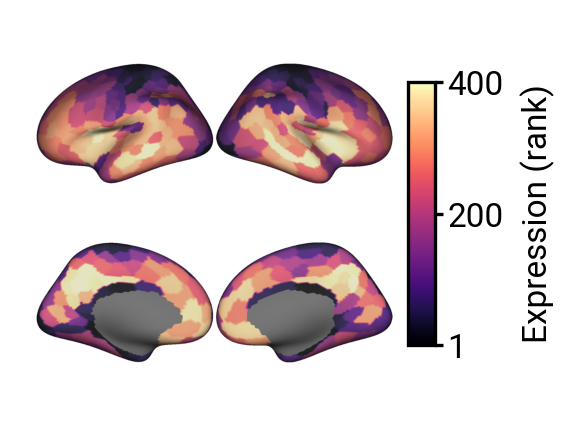

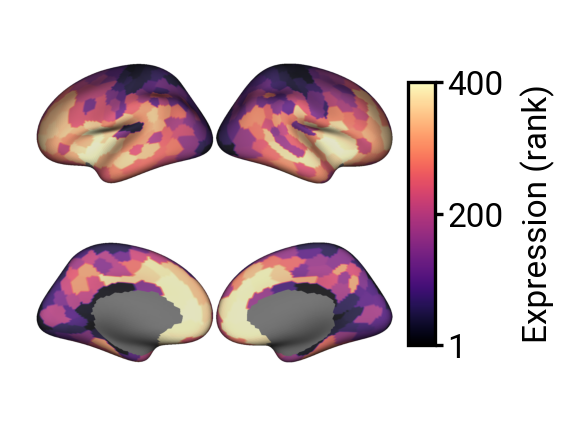

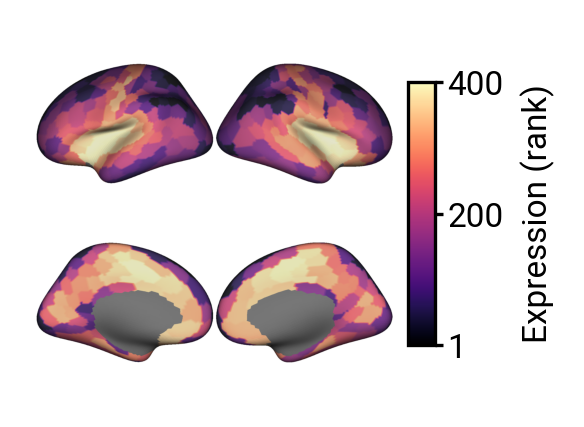

In [15]:
if not left_hemi:
    for col in plot_cols:
    # for col in df_neuro.columns:
        out_file = os.path.join(nas_scratch_dir, f'{col}.png')

        if 'PCA' in col:
            data_vector = df_neuro[col].values
            cmap = 'coolwarm'
            symmetric_cbar = True
            cbar_label = 'PC Score'
        else:
            data_vector = sp.stats.rankdata(df_neuro[col], nan_policy='omit').astype(int)
            cmap = 'magma'
            symmetric_cbar = False
            cbar_label = 'Expression (rank)'

        # if not os.path.exists(out_file):
        fig, axes = plot_brain_surface_data(
            data_vector=data_vector,
            parcellation='schaefer_400-7',
            # title=col.split('_')[1],
            title=None,
            cmap=cmap, symmetric_cbar=symmetric_cbar, cbar_label=cbar_label
        )
        plt.show()
        fig.savefig(os.path.join(nas_scratch_dir, f'{col}.png'), bbox_inches='tight', dpi=1000, transparent=True)
            
        # fig, axes = plt.subplots(nrows=1, ncols=1, sharex=False, sharey=False, figsize=(2.25, 1.75))
        # plot_correlation(sa_axis, data_vector, axes,
        #                  y_label=col,
        #                  data_group=np.asarray(yeo_systems), show_stats=True, fontsize=8, method='spearman',
        #                  size=15,
        #                  cbar_label='Yeo Systems',
        #                  auto_polynomial=True, models_to_test=[1,], model_selection_metric='variance_explained')
        # plt.show()

# Figure 3: Deflection correlation, scatter

In [16]:
df_neuro.head()

,Inhibitory_5HT1a,Inhibitory_5HT1b,Excitatory_5HT2a,Excitatory_5HT4,Excitatory_5HT6,Transporter_5HTT,Excitatory_A4B2,Inhibitory_CB1,Excitatory_D1,Inhibitory_D2,...,Inhibitory_H3,Excitatory_M1,Excitatory_mGluR5,Inhibitory_MOR,Transporter_NET,Excitatory_NMDA,Transporter_VAChT,Mean_Inhibitory,Mean_Excitatory,Mean_Transporter
0,1.614237,-1.551524,-0.622990,-0.332484,-0.402850,-0.148633,0.111111,0.405421,1.377349,0.664718,...,-0.280807,-1.452824,-0.222367,0.165875,-0.591126,0.665970,-0.191840,0.228763,-0.109886,-0.012782
1,3.305001,-1.909693,-0.477938,0.115878,0.054898,1.102549,-0.374434,0.743488,1.181265,1.431553,...,-0.379831,0.002905,0.500693,-0.119417,-0.622328,0.241969,0.157440,0.503121,0.155654,0.520375
2,0.698153,-0.827148,-0.612888,-0.605931,-0.069260,-0.535546,0.516099,0.442204,0.247319,-0.064984,...,-0.295113,-1.381489,-0.549766,-0.531764,-0.008628,0.935856,-0.276512,0.001680,-0.190008,-0.070570
3,-0.110659,-0.721145,-0.180204,-0.180539,0.195876,0.446339,0.219247,-0.181284,1.036256,0.116494,...,-0.612207,-0.405848,-0.044645,-0.966043,-0.060369,1.162613,-0.180475,-0.149519,0.225345,0.198754
4,-0.863915,-0.438107,-0.419356,-0.535125,0.205776,-0.083110,0.331499,-0.405958,0.557038,-0.241343,...,-0.572249,-0.606494,-0.716760,-1.623782,0.070676,0.987789,-0.537521,-0.404305,-0.024454,0.040323


In [17]:
results = compute_deflections_glm(df_ints.loc[:,reference], df_ints.loc[:,condition], df_neuro, standardize=True)

In [18]:
import statsmodels.api as sm

# For each PET map, compute a null distribution of correlations by:
#   1. Partialing rest INT out of each BrainSMASH surrogate map
#   2. Correlating the null feature partial residual with the observed task partial residual
# This preserves the spatial autocorrelation of the receptor maps under H0.
rest_vals = df_ints[reference].values

null_corrs = {}
for col in tqdm(df_neuro.columns, desc='Null correlations'):
    nulls      = brainsmash_nulls[col]          # (n_perms, n_regions)
    task_resid = results[col]['task_partial_resid']  # observed, (n_regions,)
    perm_r     = np.full(n_perms, np.nan)

    for i in range(n_perms):
        null_map = nulls[i]
        valid = ~(np.isnan(null_map) | np.isnan(rest_vals) | np.isnan(task_resid))
        if valid.sum() < 3:
            continue
        # partial out rest INT from the null receptor map
        X = sm.add_constant(rest_vals[valid])
        null_feature_resid = sm.OLS(null_map[valid], X).fit().resid
        perm_r[i], _ = sp.stats.pearsonr(null_feature_resid, task_resid[valid])

    null_corrs[col] = perm_r

# Pre-compute one-tailed permutation p-values for every map
null_pvals = {}
for col in df_neuro.columns:
    x = results[col]['feature_partial_resid']
    y = results[col]['task_partial_resid']
    valid = ~(np.isnan(x) | np.isnan(y))
    obs_r, _ = sp.stats.pearsonr(x[valid], y[valid])
    null = null_corrs[col]
    if obs_r >= 0:
        null_pvals[col] = float(np.mean(null >= obs_r))
    else:
        null_pvals[col] = float(np.mean(null <= obs_r))

print('Example null p-values:', {k: f'{v:.3f}' for k, v in list(null_pvals.items())[:4]})

Null correlations: 100%|██████████| 22/22 [00:21<00:00,  1.01it/s]

Example null p-values: {'Inhibitory_5HT1a': '0.072', 'Inhibitory_5HT1b': '0.236', 'Excitatory_5HT2a': '0.161', 'Excitatory_5HT4': '0.001'}


In [19]:
results[col].keys()

dict_keys(['model', 'coef', 'pvalue', 'tstat', 'conf_int', 'r_squared', 'r_squared_adj', 'task_partial_resid', 'feature_partial_resid', 'valid_mask'])

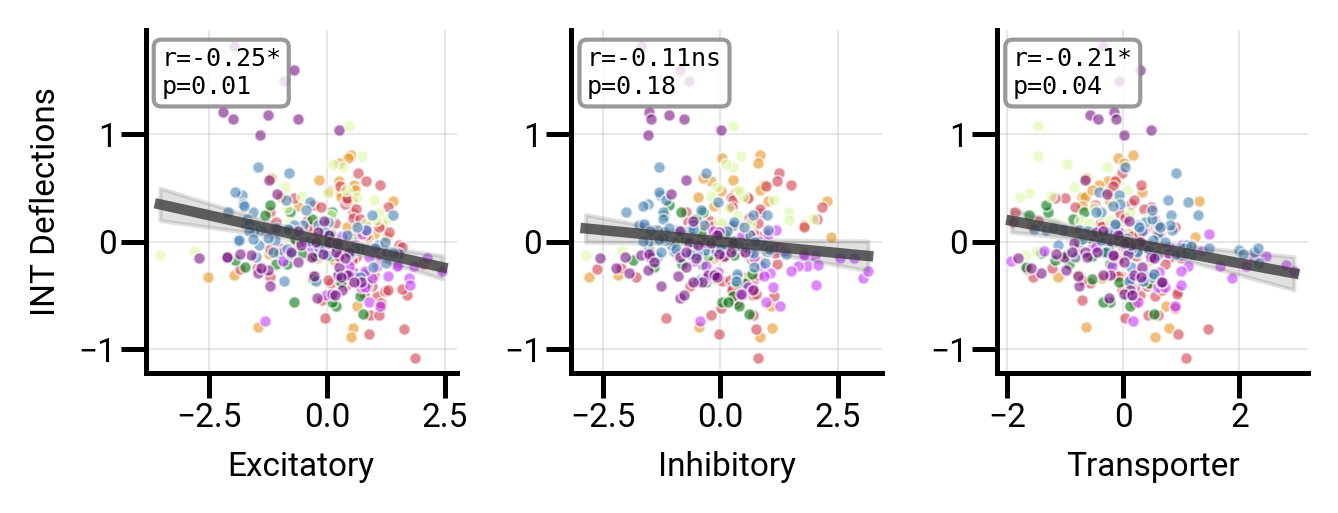

In [20]:
fig, axes = plt.subplots(nrows=1, ncols=len(plot_cols),
                         sharex=False, sharey=False,
                         figsize=(len(plot_cols)*1.5, 1.75), dpi=300)

for i, col in enumerate(plot_cols):
    x_glm = pd.Series(results[col]['feature_partial_resid'], name=col)
    y_glm = pd.Series(results[col]['task_partial_resid'], name='INT Deflections')
    plot_correlation(x_glm, y_glm, axes[i],
                     x_label=col.split('_')[1],
                     data_group=np.asarray(yeo_systems),
                     show_stats=True, fontsize=8, method='pearson',
                     size=8, cbar_label='Yeo Systems', show_colorbar=False, data_group_cmap='yeo7',
                     auto_polynomial=False, models_to_test=[1,], model_selection_metric='variance_explained',
                     custom_pvalue=null_pvals[col])
    if i != 0:
        axes[i].set_ylabel('')

for ax in axes:
    ax.tick_params(axis='y', which='major', pad=1)
    ax.tick_params(axis='x', which='major', pad=1)

fig.tight_layout()
fig.savefig(os.path.join(nas_scratch_dir, f'corr_intdelta_neurobio.svg'), bbox_inches='tight', dpi=300, transparent=True)
plt.show()


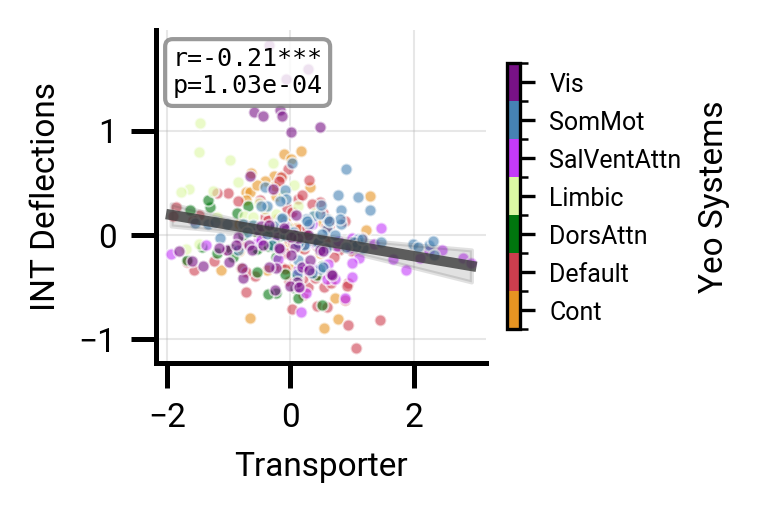

In [21]:
fig, axes = plt.subplots(nrows=1, ncols=1,
                         sharex=False, sharey=False,
                         figsize=(2.5, 1.75), dpi=300)

plot_correlation(x_glm, y_glm, axes,
                    x_label=col.split('_')[1],
                    data_group=np.asarray(yeo_systems),
                    show_stats=True, fontsize=8, method='pearson',
                    size=8, cbar_label='Yeo Systems', show_colorbar=True, data_group_cmap='yeo7',
                    auto_polynomial=False, models_to_test=[1,], model_selection_metric='variance_explained')
    
fig.tight_layout()
fig.savefig(os.path.join(nas_scratch_dir, f'corr_intdelta_neurobio_cbar.svg'), bbox_inches='tight', dpi=300, transparent=True)
plt.show()

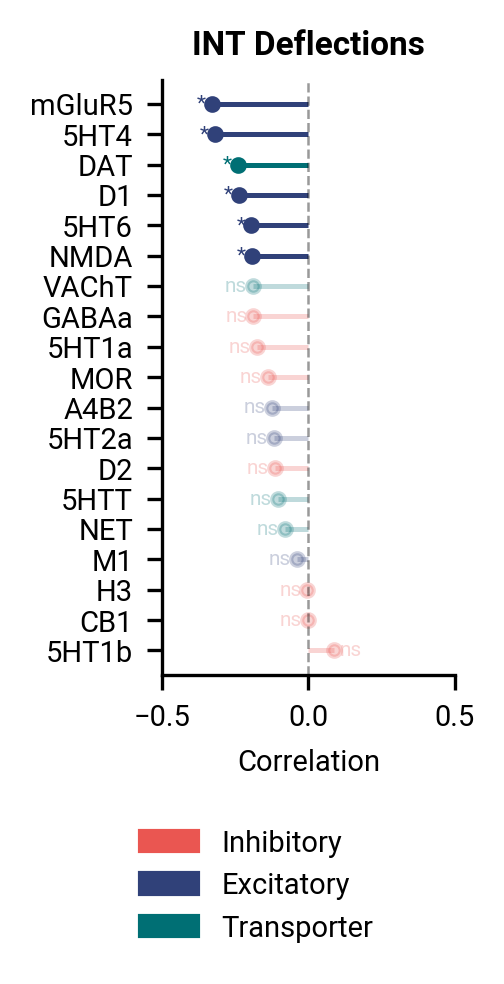

In [22]:
# Build correlation results from GLM partial residuals.
# P-values are from BrainSMASH spatial permutation tests (one-tailed).
df_results = pd.DataFrame(index=pet_categories.index, columns=['INT Deflections'], dtype=float)
df_pvals   = pd.DataFrame(index=pet_categories.index, columns=['INT Deflections'], dtype=float)

for col in pet_categories.index:
    x = results[col]['feature_partial_resid']
    y = results[col]['task_partial_resid']
    valid = ~(np.isnan(x) | np.isnan(y))
    corr, _ = sp.stats.pearsonr(x[valid], y[valid])
    df_results.loc[col, 'INT Deflections'] = corr
    df_pvals.loc[col,   'INT Deflections'] = null_pvals[col]

fig, axes = plot_faceted_lollipops(df_results, df_pvals, category_colors=my_colors,
                                   figsize=(1.75, 3.25), markersize=3, fontsize=8,
                                   show_legend=True, annotate_sig=True, nonsig_alpha=0.25)
df_results.to_csv(os.path.join(nas_scratch_dir, 'df_results_delta.csv'))
df_pvals.to_csv(os.path.join(nas_scratch_dir, 'df_pvals_delta.csv'))
fig.savefig(os.path.join(nas_scratch_dir, 'corr_intdelta_neurobio_lollipop.svg'), bbox_inches='tight', dpi=300, transparent=True)
plt.show()
